# Audio Pipeline and Voiceprint Model

**Role C: audio lead.** This notebook walks through the audio part of the system: loading the voice recordings, plotting and interpreting them, augmenting them, extracting features into `audio_features.csv`, and training the voiceprint verification model.

All logic lives in `src/audio_processing.py` and `src/train_voice_model.py`; the notebook calls those scripts so the notebook and the command-line app always agree.

Run it locally from the repository (`pip install -r requirements.txt` first).

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

import audio_processing as ap
import train_voice_model as tv

## 1. Recordings

Each of the three members with recordings (Denyse, Nick, Placide) recorded the two phrases **"Yes, approve"** and **"Confirm transaction"** twice on a phone (`.m4a`, 48 kHz): 12 member recordings. Two people outside the team recorded one clip each (`Diff.m4a`, `Unknown-2.m4a`); these are the unauthorized samples.

Every recording is converted to the same format before anything else:

- resampled to **16 kHz mono** (speech carries very little information above 8 kHz),
- **silence trimmed** from both ends (anything 30 dB below the peak),
- **peak-normalised**, so loudness differences between phones do not leak into the features,
- saved as `media/audio/original/<member>_<phrase>_<take>.wav` (non-members go to `media/audio/unauthorized/`).

In [2]:
manifest = ap.convert_raw_recordings()
manifest

,raw_file,member,phrase,wav,seconds
0,denyse_Confirm.m4a,denyse,confirm_transaction,media/audio/original/denyse_confirm_transactio...,1.70
1,Denyse_confirm_2.m4a,denyse,confirm_transaction,media/audio/original/denyse_confirm_transactio...,1.50
2,denyse_Yes_approve.m4a,denyse,yes_approve,media/audio/original/denyse_yes_approve_1.wav,2.30
3,denyse_Yes_approve_2.m4a,denyse,yes_approve,media/audio/original/denyse_yes_approve_2.wav,2.14
4,Nick-transaction.m4a,nick,confirm_transaction,media/audio/original/nick_confirm_transaction_...,1.76
5,Nick-transaction-2.m4a,nick,confirm_transaction,media/audio/original/nick_confirm_transaction_...,2.94
6,Nick-approve.m4a,nick,yes_approve,media/audio/original/nick_yes_approve_1.wav,1.73
7,Nick-approve-2.m4a,nick,yes_approve,media/audio/original/nick_yes_approve_2.wav,2.31
8,Placide_Confirm.m4a,placide,confirm_transaction,media/audio/original/placide_confirm_transacti...,1.60
9,placide_confirm_2.m4a,placide,confirm_transaction,media/audio/original/placide_confirm_transacti...,1.50


## 2. Waveforms and spectrograms

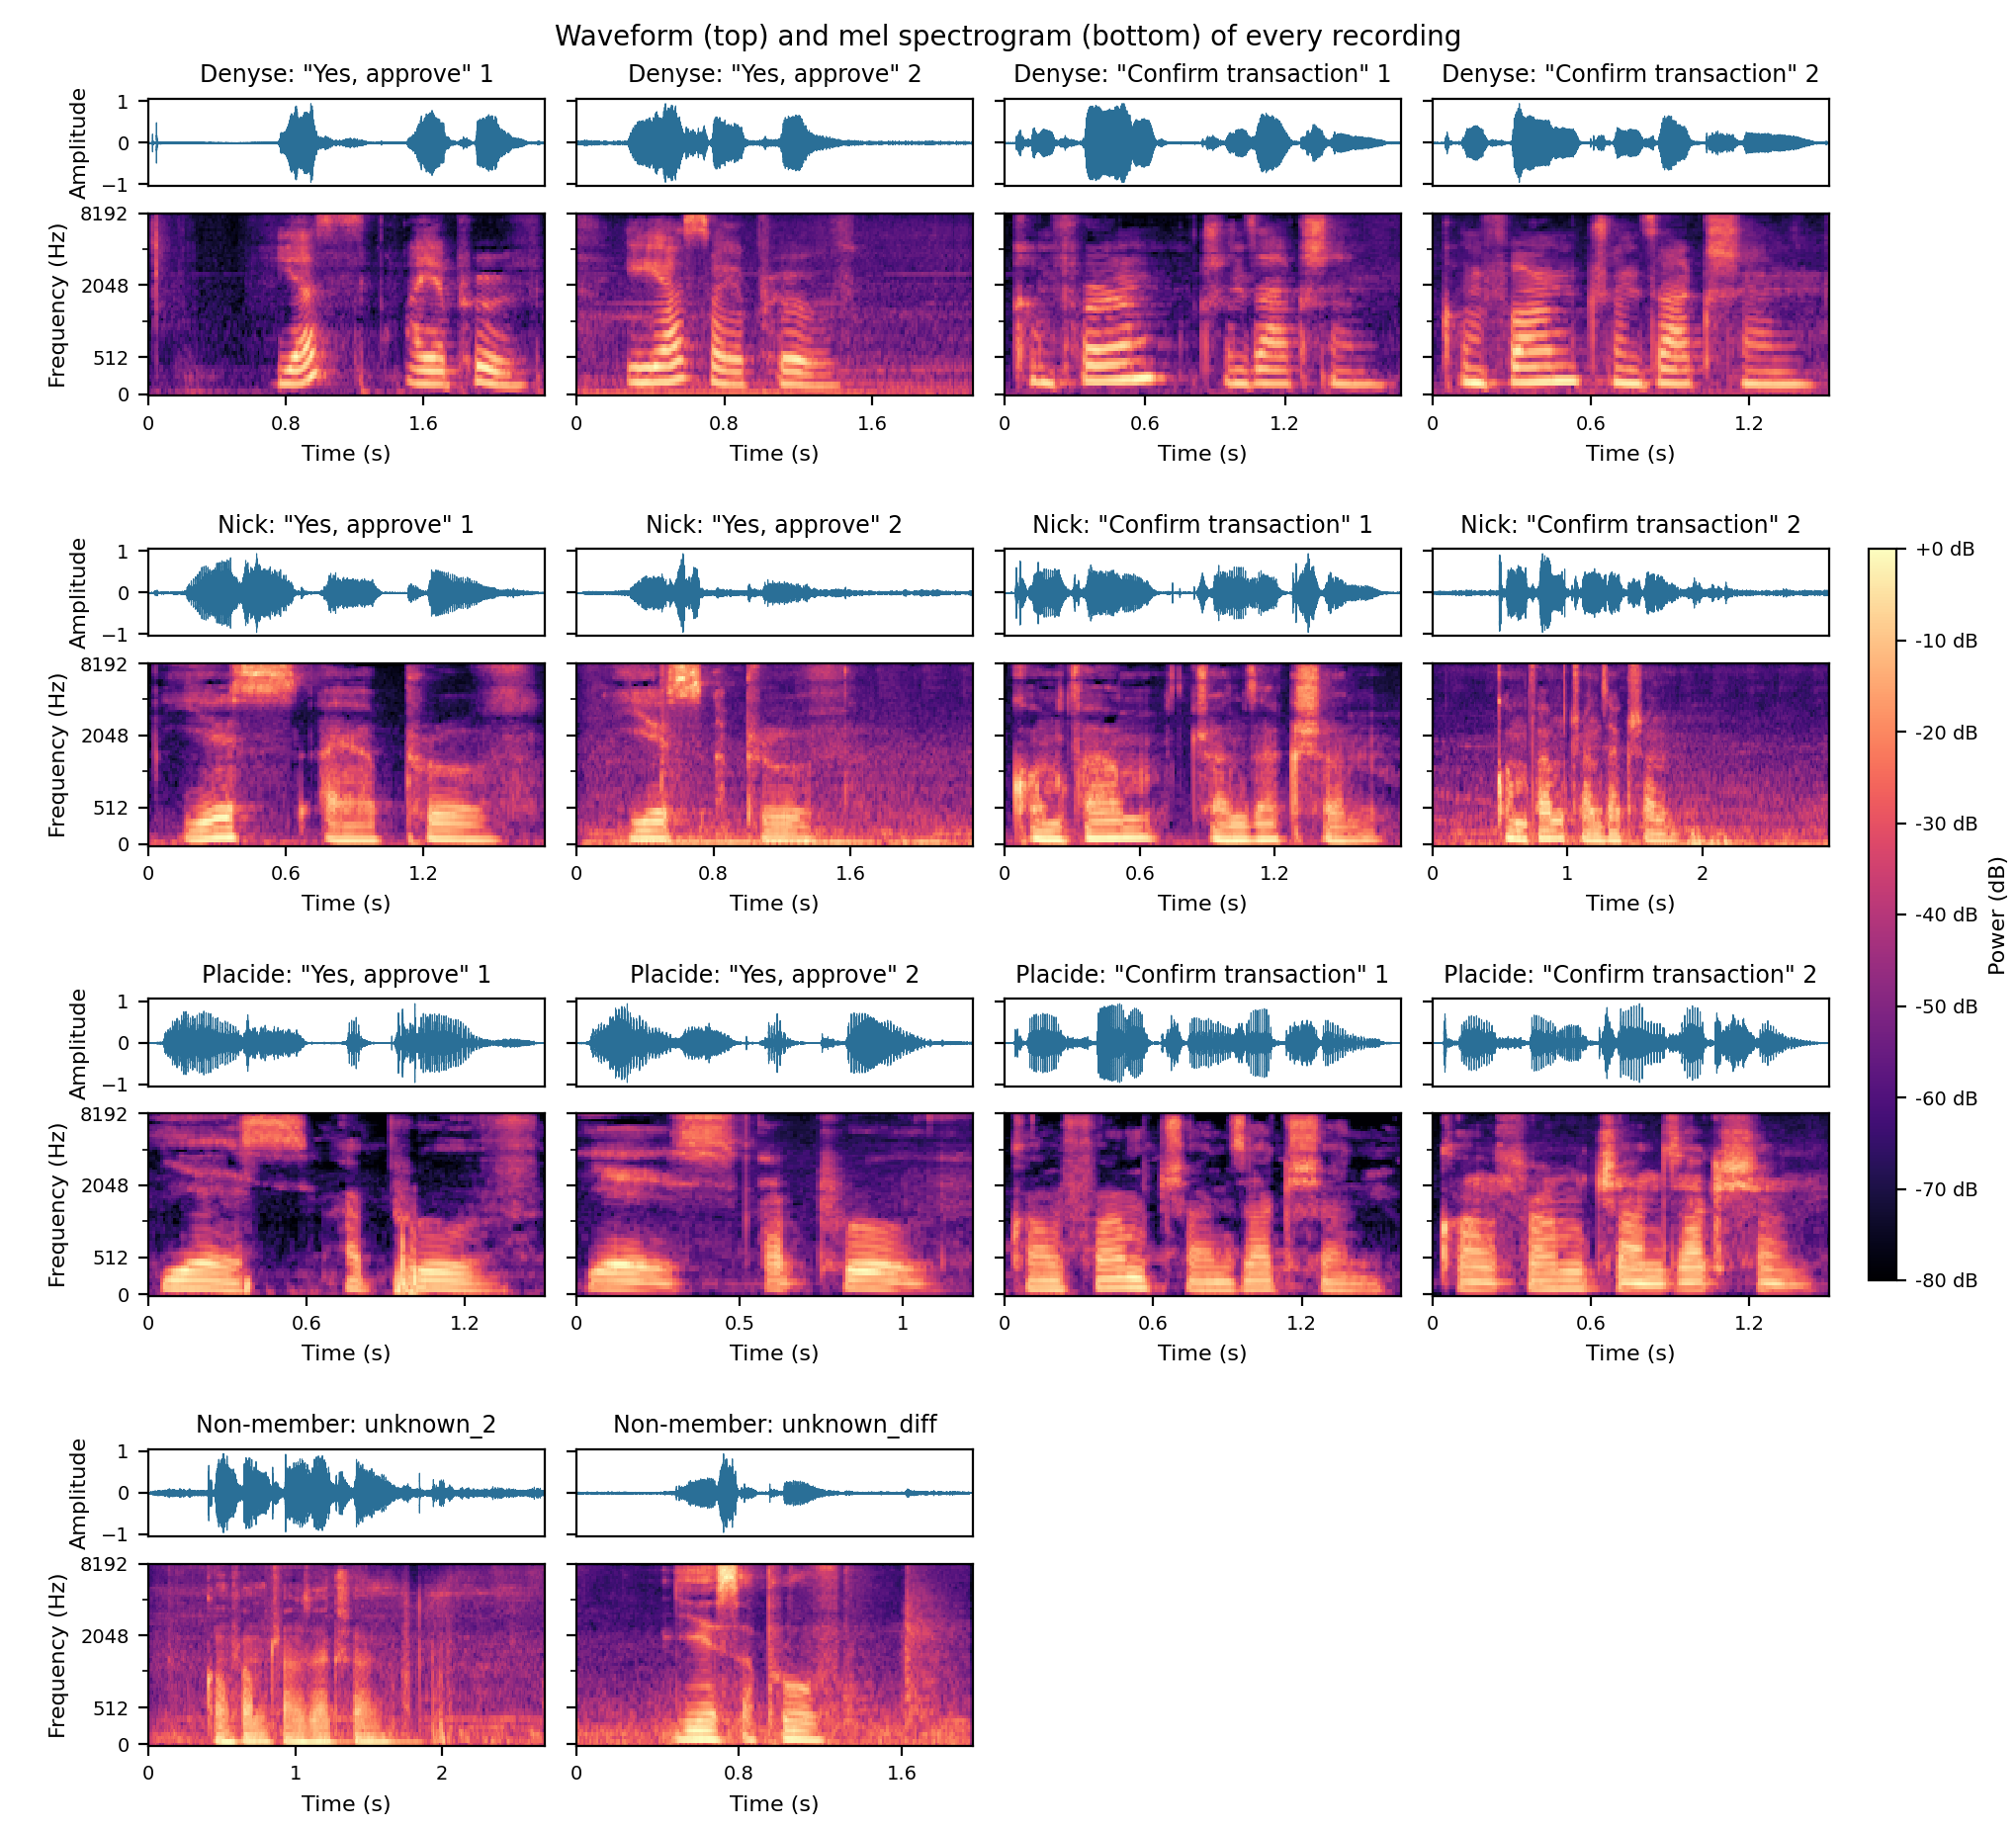

In [3]:
display(Image(ap.plot_waveforms_and_spectrograms()))

**Interpretation**

- **Waveforms (left).** Each burst is a syllable. "Confirm transaction" (5 syllables) shows more bursts than "Yes, approve" (3). In most member recordings the gaps between words drop to almost zero amplitude, so the background is quiet. After trimming, clips last 1.2 to 2.9 s.
- **Spectrograms (right).** The horizontal stripes are the harmonics of the speaker's pitch, visible during vowels. Denyse's stripes are widely spaced (mean pitch 135 to 206 Hz across her four recordings) while Nick's (83 to 109 Hz) and Placide's (101 to 111 Hz) are tightly packed. The bright columns reaching 8 kHz are the hissing consonants ("s" in *yes*, "s" and "sh" in *transaction*). Most of the energy sits below 1 kHz.
- **Quality issues found.** (1) Denyse's first "Yes, approve" starts with a click followed by about 0.7 s of silence; the click is loud, so the trimmer keeps it. (2) Nick's second takes were recorded in a noisier room: the spectrogram never goes dark, and "Confirm transaction" take 2 keeps about a second of room noise after the speech ends (2.9 s clip, speech ends at about 1.7 s), because the noise is louder than the trimming cut-off. (3) The `Diff` stranger clip is quiet with a visible noise floor. To stop pauses and noise from distorting the features, feature statistics are computed over **voiced frames only** (section 4).
- **Consequence for the model.** Pitch alone separates Denyse from the others, but Nick, Placide and both strangers have similar, low pitch, so the model must rely on the spectral shape (MFCCs) to tell them apart.

## 3. Augmentation

Each clip gets six augmented copies (three techniques, two settings each), saved in `media/audio/augmented/`:

| Augmentation | Setting | Simulates |
|---|---|---|
| Pitch shift | +1 / -1 semitone | natural day-to-day variation in a voice |
| Time stretch | 15% faster / 15% slower | speaking faster or slower |
| Background noise | white noise at 20 dB / 10 dB SNR | a quiet room / a noisy room |

The pitch shift is kept small on purpose: a large shift would turn one speaker's voice into something closer to another person's, which is the opposite of what a voiceprint model should learn.

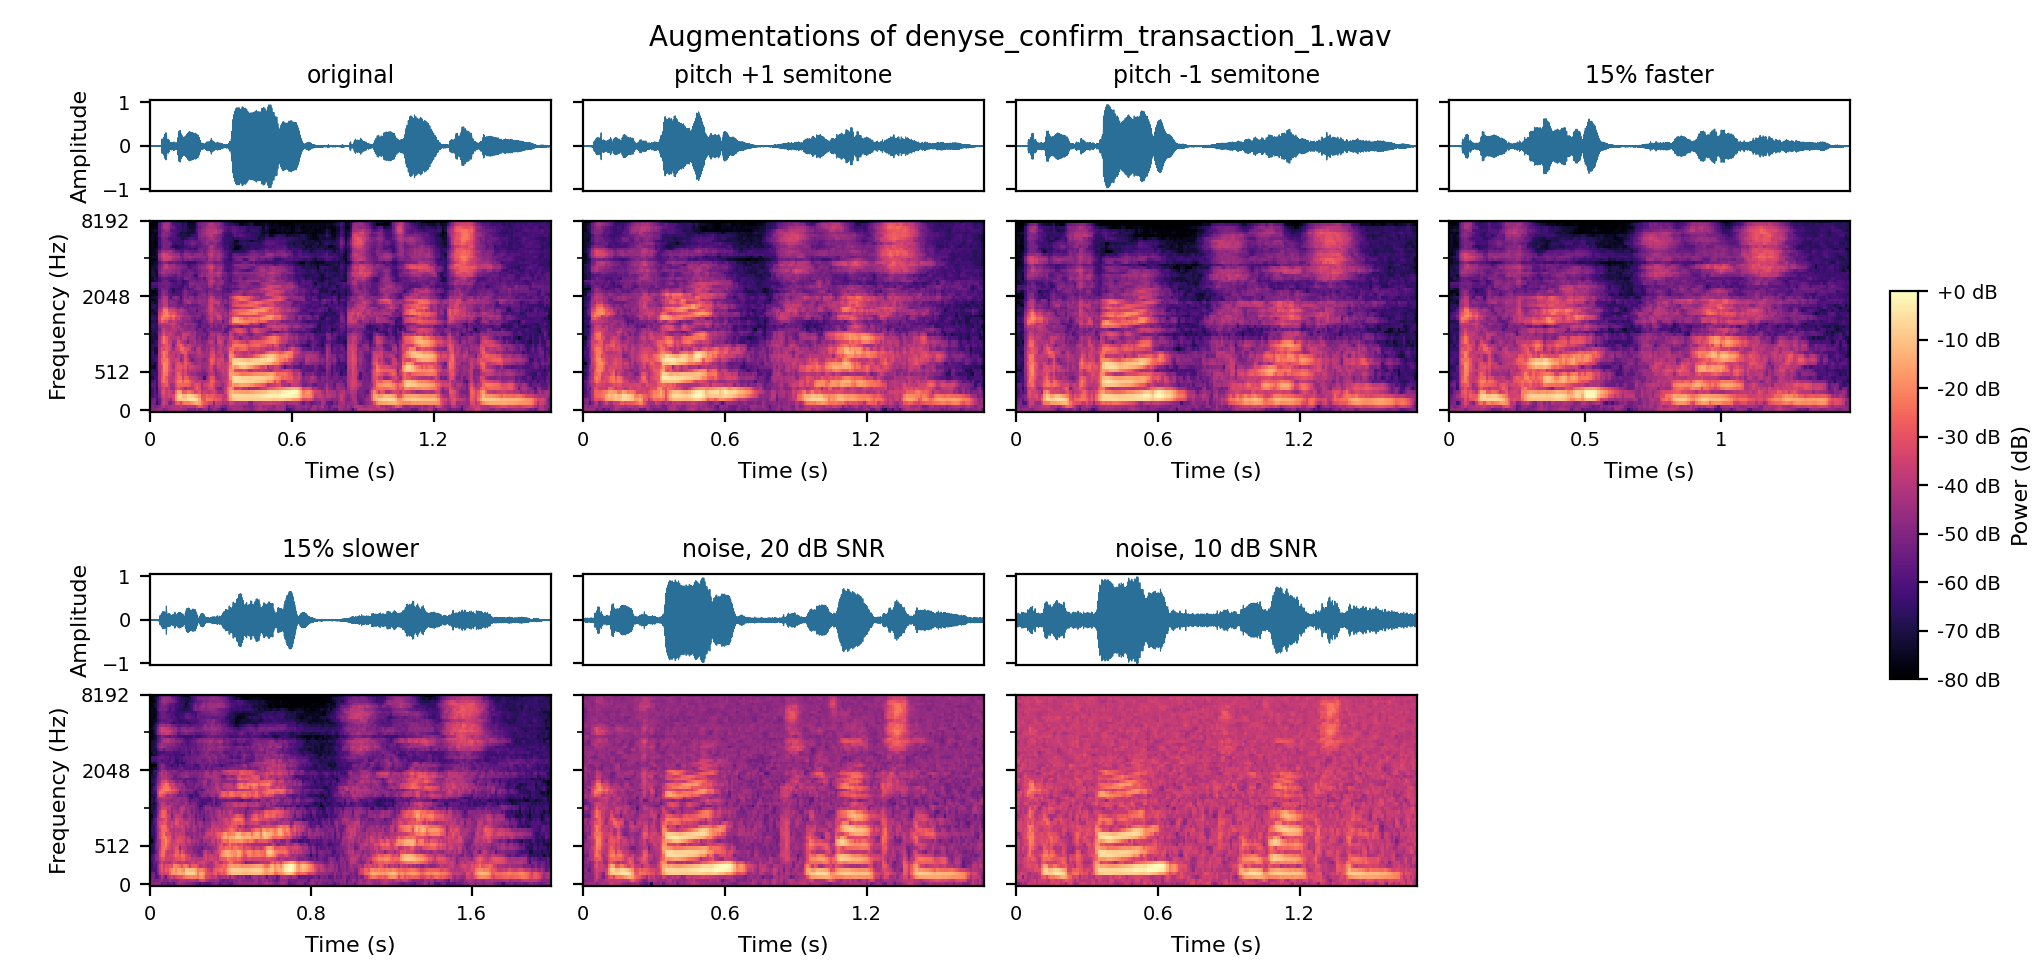

In [4]:
display(Image(ap.plot_augmentations()))

**Interpretation.** Pitch shifting moves the harmonic stripes up or down without changing the duration. Time stretching changes the duration (1.47 s and 2.00 s against the original 1.70 s) without moving the stripes. Noise fills the dark (silent) regions of the spectrogram; at 10 dB the weaker high-frequency consonants are almost buried, which is why this is the hardest augmentation for the model.

## 4. Feature extraction → `audio_features.csv`

Frame-level features are computed every 10 ms and summarised per clip by their mean and standard deviation over the voiced frames:

| Feature group | Columns | What it captures |
|---|---|---|
| MFCCs (13) | `mfcc_i_mean`, `mfcc_i_std` | shape of the vocal tract (the core voiceprint feature) |
| Delta MFCCs (13) | `delta_mfcc_i_std` | how fast the spectrum changes |
| Spectral roll-off, centroid, bandwidth | `*_mean`, `*_std` | brightness of the voice |
| RMS energy | `rms_energy_mean`, `rms_energy_std` | loudness and its variation |
| Zero-crossing rate | `zcr_mean`, `zcr_std` | noisiness |
| Pitch | `f0_mean`, `f0_std`, `voiced_fraction` | how high the voice is |
| Duration | `duration_s` | clip length |

In [5]:
features = ap.build_feature_table()
features.to_csv(ap.FEATURES_PATH, index=False)
print("shape:", features.shape, "| missing values:", int(features.isna().sum().sum()))
print(features.groupby("member")["augmentation"].count().rename("clips"))
features[features["is_original"] == 1][
    ["member", "phrase", "duration_s", "f0_mean", "voiced_fraction", "rolloff_mean", "rms_energy_mean", "mfcc_1_mean"]
].round(2)

shape: (98, 59) | missing values: 0
member
denyse     28
nick       28
placide    28
unknown    14
Name: clips, dtype: int64


,member,phrase,duration_s,f0_mean,voiced_fraction,rolloff_mean,rms_energy_mean,mfcc_1_mean
0,denyse,confirm_transaction,1.70,206.16,0.69,2606.84,0.16,105.67
7,denyse,confirm_transaction,1.50,192.83,0.77,2470.62,0.13,113.25
14,denyse,yes_approve,2.30,193.96,0.40,2979.17,0.16,101.13
21,denyse,yes_approve,2.14,135.40,0.73,3798.57,0.11,87.85
28,nick,confirm_transaction,1.76,109.18,0.63,1679.90,0.18,141.54
35,nick,confirm_transaction,2.94,83.66,0.77,2267.54,0.10,121.51
42,nick,yes_approve,1.73,104.30,0.55,2765.30,0.15,121.56
49,nick,yes_approve,2.31,82.94,0.80,3841.90,0.05,87.91
56,placide,confirm_transaction,1.60,111.49,0.69,1947.64,0.16,146.85
63,placide,confirm_transaction,1.50,101.30,0.72,2195.53,0.13,141.87


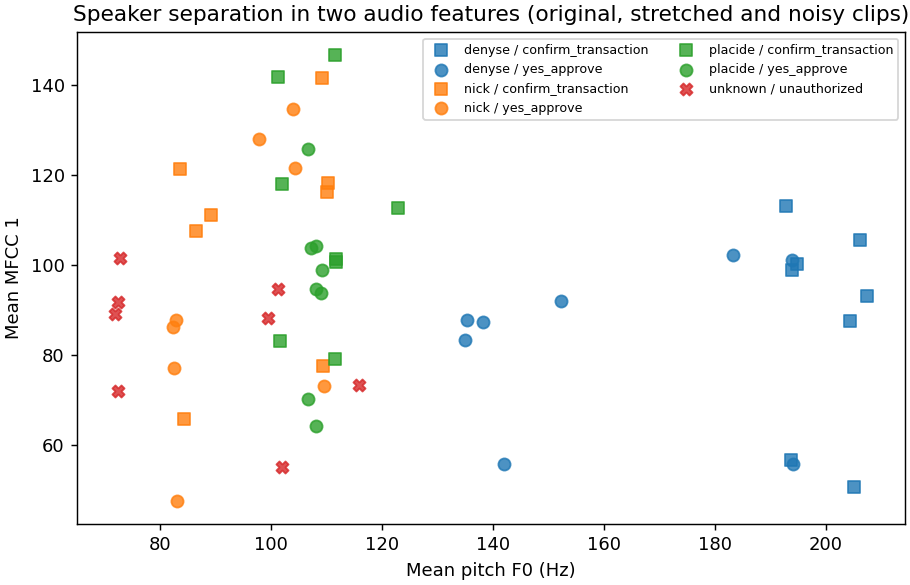

In [6]:
display(Image(ap.plot_feature_separation(features)))

**Interpretation.** The table confirms what the spectrograms showed: Denyse's mean pitch is well above Nick's and Placide's. The second stranger (`unknown_2`) has the lowest pitch of all (73 Hz), close to Nick's second takes (83 Hz). In the scatter plot Denyse forms her own cluster on the right, while Nick, Placide and both strangers overlap on the left. These are the hard cases for the model.

## 5. Voiceprint verification model

**Task.** Identify which member is speaking. A voice is only *verified* when the model's confidence reaches a threshold; otherwise the result is `unknown` and access is denied.

**Evaluation: leave-one-recording-out.** A recording is held out together with all six of its augmented copies, so the model is always tested on a recording it has never heard in any form. Splitting the clips at random would put augmented copies of the same recording in both train and test and report near-perfect, meaningless scores.

**Feature sets compared.** *All features* against *long-term averages* (only the `*_mean` columns). Standard deviations, deltas and duration describe how one particular phrase unfolds rather than who is speaking.

**Threshold.** Chosen from the held-out predictions as the confidence that best separates correct identifications from wrong ones. The unauthorized clip is never used for training or for choosing the threshold; it is a separate test.

In [7]:
tv.main()

members: ['denyse', 'nick', 'placide'] | clips: 84 from 12 recordings | features: {'all features': 53, 'long-term averages': 19}



Leave-one-recording-out CV:
                      model           features  accuracy  f1_macro  log_loss  selected
    Baseline (class priors)       all features     0.000     0.000     1.299     False
Logistic Regression (C=0.1)       all features     0.810     0.810     0.460      True
              Random Forest       all features     0.810     0.806     0.597     False
                  SVM (RBF)       all features     0.786     0.789     0.522     False
Logistic Regression (C=0.1) long-term averages     0.738     0.728     0.554     False
              Random Forest long-term averages     0.857     0.855     0.484     False
                  SVM (RBF) long-term averages     0.821     0.817     0.536     False

Selected: Logistic Regression (C=0.1) on all features | confidence threshold: 0.651
  unseen member recordings verified correctly: 57%
  unseen member recordings rejected:           42%
  accepted under the wrong name:               1%
  enrolled (training) clips verified: 

**Interpretation**

- **Selected model.** Logistic Regression on all 53 features has the lowest log-loss: accuracy 0.81, macro-F1 0.81, log-loss 0.46 (chance is 0.33). Random Forest on the 19 long-term averages has the highest accuracy (0.86) but a higher log-loss; with 12 recordings these differences are within noise.
- **The baseline scores 0.** Holding out one of a member's four recordings makes that member the minority class in the training fold, so the class-prior baseline always predicts another member. Its log-loss (1.30) is the useful reference.
- **The second takes helped every model.** With one take per phrase (6 recordings), the best accuracy was 0.71 and models on all features scored 0.40 to 0.45. With two takes per phrase, all models score 0.74 to 0.86.
- **Errors.** Denyse is recognised in 26 of her 28 held-out clips. Most errors are between Nick and Placide, the two voices with similar pitch (8 of Nick's 28 clips are predicted as Placide).
- **Threshold.** At 0.65, 1% of held-out member clips are accepted under the wrong name, at the cost of rejecting 42% of them. For an approval step, wrongly denying a member is the safer error. All enrolled (training) clips are verified.
- **Unauthorized test.** The `Diff` stranger is rejected (confidence 0.46), as are 4 of its 6 augmented copies. The second stranger is **accepted as Nick with confidence 0.95**, and so are all its augmented copies. Every candidate model does the same. In these features that voice is as close to Nick's recordings as Nick's own takes are to each other, and a closed-set classifier's confidence only says which member is closest, not how close. Training an extra "unknown" class on the other stranger did not fix it. In the full system this stranger would also need to pass face recognition as Nick, because the CLI requires the face and voice identities to match.
- **How to improve it.** More non-member voices to test rejection properly, more takes per member, and a verification step that measures the distance to the claimed member's enrolled recordings (for example with a pretrained speaker-embedding model) instead of relying on classifier confidence alone.

## 6. Interface for the CLI

`predict_voice(audio_path)` in `src/predict.py` returns `(member_name or "unknown", confidence)`. It accepts any audio file and runs the same cleaning and feature extraction as above.

In [8]:
from predict import predict_voice

for path in sorted((ROOT / "media" / "audio").glob("*.m4a")):
    name, conf = predict_voice(path)
    print(f"{path.name:26s} -> {name:8s} (confidence {conf:.2f})  {'VERIFIED' if name != 'unknown' else 'ACCESS DENIED'}")

Denyse_confirm_2.m4a       -> denyse   (confidence 0.93)  VERIFIED
Diff.m4a                   -> unknown  (confidence 0.46)  ACCESS DENIED


Nick-approve-2.m4a         -> nick     (confidence 0.98)  VERIFIED
Nick-approve.m4a           -> nick     (confidence 0.89)  VERIFIED


Nick-transaction-2.m4a     -> nick     (confidence 0.97)  VERIFIED
Nick-transaction.m4a       -> nick     (confidence 0.93)  VERIFIED
Placide_Confirm.m4a        -> placide  (confidence 0.97)  VERIFIED


Placide_Yes_approve.m4a    -> placide  (confidence 0.98)  VERIFIED
Unknown-2.m4a              -> nick     (confidence 0.95)  VERIFIED


denyse_Confirm.m4a         -> denyse   (confidence 0.98)  VERIFIED
denyse_Yes_approve.m4a     -> denyse   (confidence 0.93)  VERIFIED


denyse_Yes_approve_2.m4a   -> denyse   (confidence 0.94)  VERIFIED
placide_confirm_2.m4a      -> placide  (confidence 0.96)  VERIFIED
placide_yes_approve_2.m4a  -> placide  (confidence 0.98)  VERIFIED
